# Music ticket prices — exploration of `data/music.db`

Exploratory analysis of the Gametime music price snapshots (`gametime` table), aimed at
**predicting ticket price**. Two candidate targets are compared throughout:

- `minPrice` — cheapest "get-in" price (with fees)
- `medianPrice` — typical listing price (with fees)

**Grain:** one row = one event × one snapshot day. Heavy aggregations run in SQLite; plots that
need row-level data use a deterministic ~10% sample (`rowid % 10 = 0`).

## 1. Setup

In [56]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

DB_PATH = Path("data/music.db")
conn = sqlite3.connect(DB_PATH)
TARGETS = ["minPrice", "medianPrice"]
COLORS = {"minPrice": "#4C78A8", "medianPrice": "#E45756"}


def q(sql, **params):
    """Run a SQL query against music.db and return a DataFrame."""
    return pd.read_sql_query(sql, conn, params=params)

## 2. Overview

In [57]:
q("""
SELECT COUNT(*)                  AS rows,
       COUNT(DISTINCT eventId)   AS events,
       COUNT(DISTINCT venueName) AS venues,
       COUNT(DISTINCT venueCity) AS cities,
       MIN(date)                 AS first_snapshot,
       MAX(date)                 AS last_snapshot,
       MIN(eventStartAt)         AS first_event,
       MAX(eventStartAt)         AS last_event
FROM gametime
""").T

,0
rows,1911726
events,48048
venues,3045
cities,1178
first_snapshot,2026-07-18
last_snapshot,2026-10-21
first_event,2026-07-18 05:00:00.000
last_event,2026-12-27 02:30:00.000


In [58]:
q("SELECT * FROM gametime LIMIT 5")

,_primaryKey,_firstSeenAt,_lastSeenAt,date,dayState,crawls,truncated,daysToEvent,eventId,eventName,eventStartAt,venueName,venueCity,category,eventInfoSource,section,zone,currency,listings,tickets,minPrice,p25Price,medianPrice,p75Price,maxPrice,minPriceBeforeFees,medianPriceBeforeFees,newListings,goneListings,ticketsSoldSameListing,listedTotal,reportedMinPrice,reportedMaxPrice,reportedAvgPrice
0,gametime|678feed52514480324e84940|ALL|2026-07-18,2026-07-18 00:00:00.000,2026-07-18 23:59:59.999,2026-07-18,observed,1,0,29,678feed52514480324e84940,Eden Munoz (Rescheduled from 9/13/2025),2026-08-16 01:00:00.000,The Factory STL,Chesterfield,music,events,ALL,None,None,13,None,124.00,149.00,149.00,166.00,183.00,107.00,129.00,None,None,None,None,None,None,None
1,gametime|67a537ff426d8edbfae03340|ALL|2026-07-18,2026-07-18 00:00:00.000,2026-07-18 23:59:59.999,2026-07-18,observed,1,0,7,67a537ff426d8edbfae03340,Kelly Clarkson (Rescheduled from 8/8/2025),2026-07-25 03:00:00.000,The Colosseum,Las Vegas,music,events,ALL,None,None,37,None,152.00,263.00,396.00,819.00,"3,835.00",131.00,343.00,None,None,None,None,None,None,None
2,gametime|67a537ff6eea1ad918dfc704|ALL|2026-07-18,2026-07-18 00:00:00.000,2026-07-18 23:59:59.999,2026-07-18,observed,1,0,8,67a537ff6eea1ad918dfc704,Kelly Clarkson (Rescheduled from 8/9/2025),2026-07-26 03:00:00.000,The Colosseum,Las Vegas,music,events,ALL,None,None,40,None,183.00,301.00,461.00,876.00,"28,545.00",159.00,400.00,None,None,None,None,None,None,None
3,gametime|67a537ff7bde0e9ee6b0dc1b|ALL|2026-07-18,2026-07-18 00:00:00.000,2026-07-18 23:59:59.999,2026-07-18,observed,1,0,15,67a537ff7bde0e9ee6b0dc1b,Kelly Clarkson (Rescheduled from 8/16/2025),2026-08-02 03:00:00.000,The Colosseum,Las Vegas,music,events,ALL,None,None,42,None,172.00,264.00,368.00,510.00,"7,679.00",149.00,319.00,None,None,None,None,None,None,None
4,gametime|67a537ffdd25e6e19e496356|ALL|2026-07-18,2026-07-18 00:00:00.000,2026-07-18 23:59:59.999,2026-07-18,observed,1,0,14,67a537ffdd25e6e19e496356,Kelly Clarkson (Rescheduled from 8/15/2025),2026-08-01 03:00:00.000,The Colosseum,Las Vegas,music,events,ALL,None,None,46,None,143.00,301.00,436.00,576.00,"3,897.00",124.00,378.00,None,None,None,None,None,None,None


### Column completeness and constant columns
Columns that are always null or have a single value carry no signal and can be dropped before modeling.

In [59]:
cols = q("PRAGMA table_info(gametime)")[["name", "type"]]
n_rows = q("SELECT COUNT(*) AS n FROM gametime").n[0]
stats = []
for c in cols.name:
    r = q(f'SELECT COUNT("{c}") AS non_null, COUNT(DISTINCT "{c}") AS n_unique FROM gametime')
    stats.append(r.iloc[0].to_dict())
completeness = pd.concat([cols, pd.DataFrame(stats)], axis=1)
completeness["pct_null"] = 100 * (1 - completeness.non_null / n_rows)
completeness["note"] = np.select(
    [completeness.non_null == 0, completeness.n_unique == 1],
    ["all null", "constant"], default="")
completeness

,name,type,non_null,n_unique,pct_null,note
0,_primaryKey,TEXT,1911726,1911726,0.00,
1,_firstSeenAt,TEXT,1911726,93,0.00,
2,_lastSeenAt,TEXT,1911726,93,0.00,
3,date,TEXT,1911726,93,0.00,
4,dayState,TEXT,1911726,3,0.00,
5,crawls,INTEGER,1911726,4,0.00,
6,truncated,INTEGER,1911726,1,0.00,constant
7,daysToEvent,INTEGER,1911726,155,0.00,
8,eventId,TEXT,1911726,48048,0.00,
9,eventName,TEXT,1911726,9593,0.00,


In [60]:
drop_cols = completeness.loc[completeness.note != "", "name"].tolist()
print("Uninformative columns (all-null or constant):", drop_cols)

Uninformative columns (all-null or constant): ['truncated', 'category', 'eventInfoSource', 'section', 'zone', 'currency', 'tickets', 'ticketsSoldSameListing', 'listedTotal', 'reportedMinPrice', 'reportedMaxPrice', 'reportedAvgPrice']


## 3. Data quality

`dayState` describes whether the event was actually observed on a given snapshot day. Price
columns should be null on `empty` / `unknown` days. Check this before choosing which rows to train on.

In [61]:
q("""
SELECT dayState,
       COUNT(*)                                   AS rows,
       ROUND(100.0 * COUNT(*) / SUM(COUNT(*)) OVER (), 1) AS pct_rows,
       ROUND(100.0 * AVG(minPrice IS NULL), 1)    AS pct_minPrice_null,
       ROUND(100.0 * AVG(medianPrice IS NULL), 1) AS pct_medianPrice_null,
       ROUND(AVG(tickets), 1)                     AS avg_tickets,
       SUM(truncated)                             AS truncated_rows,
       ROUND(AVG(crawls), 2)                      AS avg_crawls
FROM gametime
GROUP BY dayState
ORDER BY rows DESC
""")

,dayState,rows,pct_rows,pct_minPrice_null,pct_medianPrice_null,avg_tickets,truncated_rows,avg_crawls
0,observed,1616449,84.60,0.00,0.00,None,0,1.00
1,unknown,281936,14.70,100.00,100.00,None,0,0.00
2,empty,13341,0.70,100.00,100.00,None,0,1.00


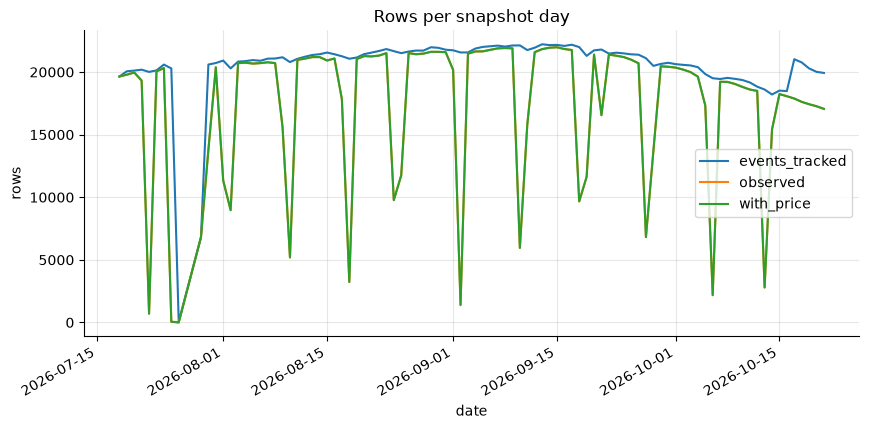

In [62]:
# Snapshot coverage over time: does the number of tracked events change by day?
daily = q("""
SELECT date,
       COUNT(*)                         AS events_tracked,
       SUM(dayState = 'observed')       AS observed,
       SUM(medianPrice IS NOT NULL)     AS with_price
FROM gametime GROUP BY date ORDER BY date
""")
daily["date"] = pd.to_datetime(daily.date)
ax = daily.plot(x="date", y=["events_tracked", "observed", "with_price"], title="Rows per snapshot day")
ax.set_ylabel("rows");

In [63]:
# Sanity checks on price ordering and impossible values
q("""
SELECT SUM(minPrice <= 0)                              AS nonpositive_min,
       SUM(minPrice > medianPrice)                     AS min_gt_median,
       SUM(p25Price > medianPrice OR medianPrice > p75Price) AS quantiles_out_of_order,
       SUM(medianPrice > maxPrice)                     AS median_gt_max,
       SUM(minPriceBeforeFees > minPrice)              AS before_fees_gt_with_fees,
       SUM(daysToEvent < 0)                            AS negative_daysToEvent,
       SUM(tickets < listings)                         AS fewer_tickets_than_listings
FROM gametime
""").T.rename(columns={0: "violations"})

,violations
nonpositive_min,0
min_gt_median,0
quantiles_out_of_order,0
median_gt_max,0
before_fees_gt_with_fees,0
negative_daysToEvent,0
fewer_tickets_than_listings,None


## 4. Load a modeling sample

Rows that are `observed` and have both target prices. `rowid % 10 = 0` gives a reproducible ~10% sample;
change `SAMPLE_MOD` to 1 to load everything (~1–2 GB RAM).

In [64]:
SAMPLE_MOD = 10

df = q(f"""
SELECT eventId, eventName, venueName, venueCity, date, eventStartAt, daysToEvent, dayState,
       listings, tickets, minPrice, p25Price, medianPrice, p75Price, maxPrice,
       minPriceBeforeFees, medianPriceBeforeFees, newListings, goneListings
FROM gametime
WHERE rowid % {SAMPLE_MOD} = 0
  AND dayState = 'observed'
  AND minPrice IS NOT NULL AND medianPrice IS NOT NULL
""")
df["date"] = pd.to_datetime(df.date)
df["eventStartAt"] = pd.to_datetime(df.eventStartAt)  # UTC timestamps
print(f"{len(df):,} rows, {df.eventId.nunique():,} events")
df.describe().T

161,487 rows, 39,744 events


,count,mean,min,25%,50%,75%,max,std
date,161487,2026-09-05 05:04:42.962715392,2026-07-18 00:00:00,2026-08-14 00:00:00,2026-09-05 00:00:00,2026-09-28 00:00:00,2026-10-21 00:00:00,NaN
eventStartAt,161487,2026-10-11 00:58:30.561841408,2026-07-18 05:00:00,2026-09-23 00:00:00,2026-10-11 03:00:00,2026-10-31 00:00:00,2026-12-26 22:30:00,NaN
daysToEvent,"161,487.00",35.57,0.00,18.00,35.00,52.00,148.00,20.56
listings,"161,487.00",18.48,1.00,1.00,5.00,19.00,424.00,34.39
minPrice,"161,487.00",97.91,4.00,50.00,67.00,96.00,"33,964.00",196.61
p25Price,"161,487.00",118.39,5.00,56.00,79.00,122.00,"33,964.00",213.16
medianPrice,"161,487.00",163.63,5.00,64.00,99.00,163.00,"36,693.00",392.64
p75Price,"161,487.00",234.61,5.00,74.00,123.00,223.00,"36,693.00",536.90
maxPrice,"161,487.00",609.12,5.00,79.00,173.00,475.00,"129,832.00","2,399.44"
minPriceBeforeFees,"161,487.00",83.09,3.00,42.00,56.00,82.00,"26,135.00",165.66


## 5. Target distributions: `minPrice` vs `medianPrice`

Both prices are heavily right-skewed, so a log transform is probably the right modeling scale.

,minPrice,medianPrice
skew,52.54,41.12
log_skew,1.28,1.03
p01,25.00,31.00
median,67.00,99.00
p99,551.14,"1,138.00"
max,"33,964.00","36,693.00"


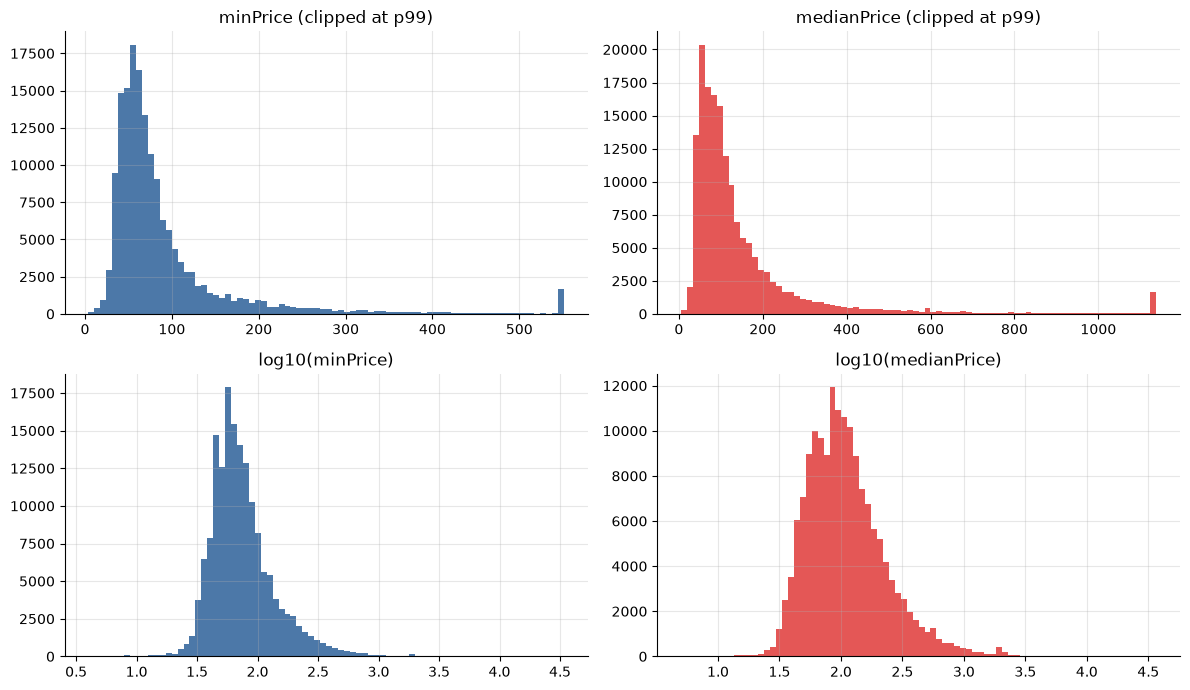

In [65]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for i, t in enumerate(TARGETS):
    x = df[t]
    axes[0, i].hist(x.clip(upper=x.quantile(0.99)), bins=80, color=COLORS[t])
    axes[0, i].set_title(f"{t} (clipped at p99)")
    axes[1, i].hist(np.log10(x), bins=80, color=COLORS[t])
    axes[1, i].set_title(f"log10({t})")
fig.tight_layout()

pd.DataFrame({t: {"skew": df[t].skew(), "log_skew": np.log10(df[t]).skew(),
                  "p01": df[t].quantile(.01), "median": df[t].median(),
                  "p99": df[t].quantile(.99), "max": df[t].max()} for t in TARGETS})

corr(log min, log median) = 0.773
median ratio median/min = 1.29


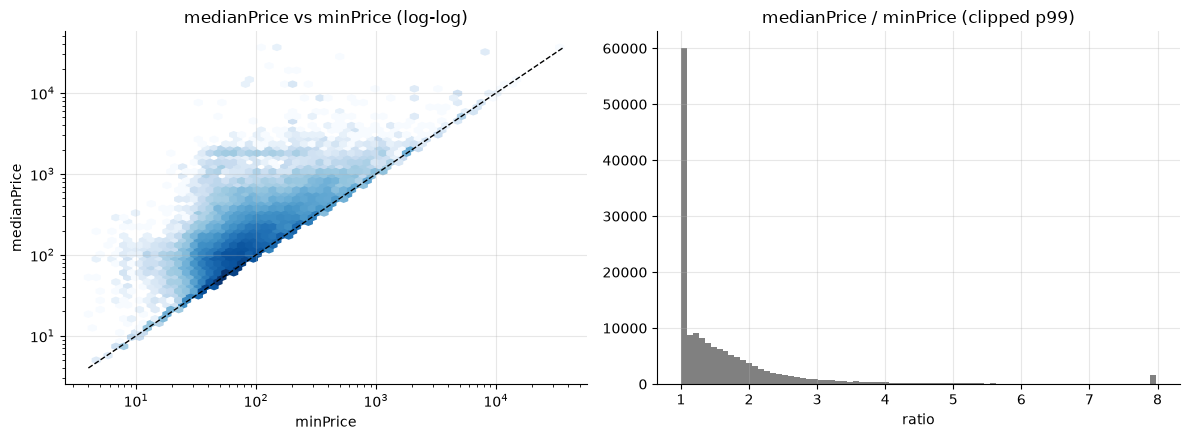

In [66]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hexbin(df.minPrice, df.medianPrice, xscale="log", yscale="log", gridsize=60, bins="log", cmap="Blues")
lims = [df[TARGETS].min().min(), df[TARGETS].max().max()]
axes[0].plot(lims, lims, "k--", lw=1)
axes[0].set(xlabel="minPrice", ylabel="medianPrice", title="medianPrice vs minPrice (log-log)")

ratio = df.medianPrice / df.minPrice
axes[1].hist(ratio.clip(upper=ratio.quantile(.99)), bins=80, color="gray")
axes[1].set(title="medianPrice / minPrice (clipped p99)", xlabel="ratio")
fig.tight_layout()
print(f"corr(log min, log median) = {np.log(df.minPrice).corr(np.log(df.medianPrice)):.3f}")
print(f"median ratio median/min = {ratio.median():.2f}")

,count,mean,std,min,25%,50%,75%,max
min_fee_mult,"161,487.00",1.18,0.04,1.11,1.16,1.17,1.19,1.89
median_fee_mult,"161,487.00",1.18,0.04,1.12,1.16,1.17,1.19,1.89


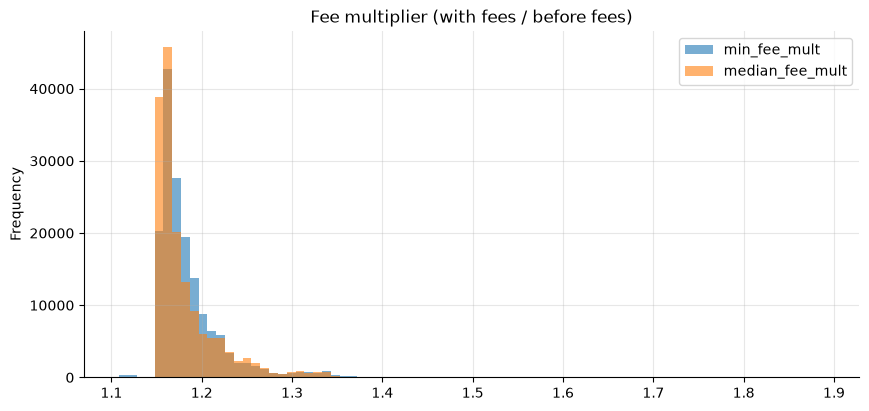

In [67]:
# Fee structure: price with fees / before fees
fee = pd.DataFrame({
    "min_fee_mult": df.minPrice / df.minPriceBeforeFees,
    "median_fee_mult": df.medianPrice / df.medianPriceBeforeFees,
})
ax = fee.clip(upper=2).plot.hist(bins=80, alpha=0.6, title="Fee multiplier (with fees / before fees)")
fee.describe().T

## 6. Price dynamics vs `daysToEvent`

Raw medians by `daysToEvent` mix different events together. The **within-event** view normalizes each
event's price by its own median across snapshots, which isolates the time effect.

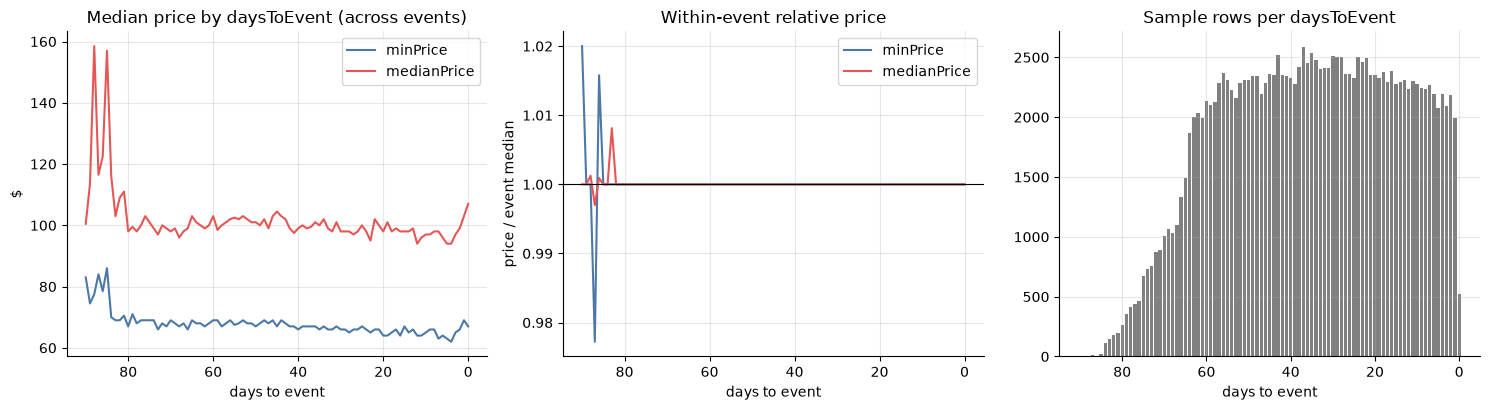

In [68]:
d = df[df.daysToEvent <= 90].copy()
for t in TARGETS:
    d[f"{t}_rel"] = d[t] / d.groupby("eventId")[t].transform("median")

by_day = d.groupby("daysToEvent").agg(
    n=("eventId", "size"),
    **{f"{t}_median": (t, "median") for t in TARGETS},
    **{f"{t}_rel": (f"{t}_rel", "median") for t in TARGETS},
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for t in TARGETS:
    axes[0].plot(by_day.index, by_day[f"{t}_median"], color=COLORS[t], label=t)
    axes[1].plot(by_day.index, by_day[f"{t}_rel"], color=COLORS[t], label=t)
axes[0].set(title="Median price by daysToEvent (across events)", xlabel="days to event", ylabel="$")
axes[1].axhline(1, color="k", lw=0.8)
axes[1].set(title="Within-event relative price", xlabel="days to event", ylabel="price / event median")
axes[2].bar(by_day.index, by_day.n, color="gray")
axes[2].set(title="Sample rows per daysToEvent", xlabel="days to event")
for ax in axes[:2]:
    ax.invert_xaxis(); ax.legend()
axes[2].invert_xaxis()
fig.tight_layout()

/opt/anaconda3/envs/predictive_modeling/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/opt/anaconda3/envs/predictive_modeling/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/opt/anaconda3/envs/predictive_modeling/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/opt/anaconda3/envs/predictive_modeling/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/opt/anaconda3/envs/predictive_modeling/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


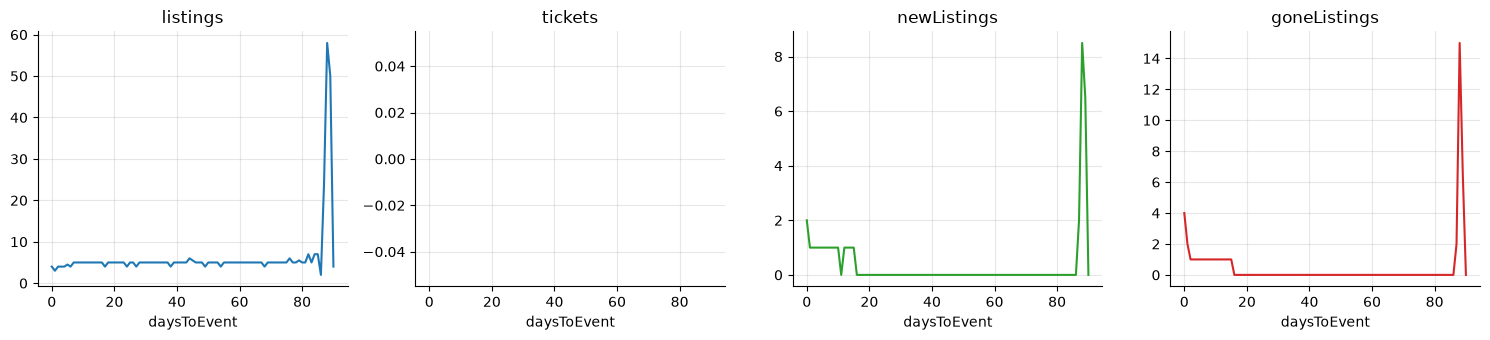

In [69]:
# Supply over the run-up: listings / tickets and churn
supply = df[df.daysToEvent <= 90].groupby("daysToEvent")[["listings", "tickets", "newListings", "goneListings"]].median()
ax = supply.plot(subplots=True, layout=(1, 4), figsize=(15, 3.5), sharex=True, legend=False,
                 title=list(supply.columns))
for a in ax.ravel():
    a.invert_xaxis()
plt.tight_layout()

## 7. Event-level features

Build one row per event (using its median prices across snapshots) so that the venues and cities with
many events don't dominate the picture.

In [70]:
events = q("""
SELECT eventId, eventName, venueName, venueCity, eventStartAt,
       COUNT(*)                         AS snapshots,
       SUM(dayState = 'observed')       AS observed_days,
       MAX(daysToEvent)                 AS max_daysToEvent,
       AVG(minPrice)                    AS avg_minPrice,
       AVG(medianPrice)                 AS avg_medianPrice,
       AVG(tickets)                     AS avg_tickets,
       AVG(listings)                    AS avg_listings
FROM gametime
GROUP BY eventId
""")
events["eventStartAt"] = pd.to_datetime(events.eventStartAt)
# eventStartAt is UTC. Shift by 5h for a rough US evening grouping (no venue timezone available).
local = events.eventStartAt - pd.Timedelta(hours=5)
events["weekday"] = local.dt.day_name()
events["month"] = local.dt.to_period("M").astype(str)
events = events.dropna(subset=["avg_medianPrice"])
print(f"{len(events):,} events with prices")
events.describe().T

46,180 events with prices


/var/folders/yv/g_9pwhts5jvb7m7p1fvjvfzr0000gp/T/ipykernel_52184/2680083144.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`).Please use a specific unit instead.
  local = events.eventStartAt - pd.Timedelta(hours=5)


,count,mean,min,25%,50%,75%,max,std
eventStartAt,46180,2026-10-07 00:20:54.819445760,2026-07-18 05:00:00,2026-09-06 18:00:00,2026-10-09 00:00:00,2026-11-08 01:00:00,2026-12-27 02:30:00,NaN
snapshots,"46,180.00",41.21,1.00,19.00,40.00,62.00,92.00,24.19
observed_days,"46,180.00",35.00,1.00,16.00,35.00,53.00,79.00,20.74
max_daysToEvent,"46,180.00",54.46,0.00,38.75,63.00,70.00,154.00,22.82
avg_minPrice,"46,180.00",111.05,6.80,52.20,71.08,106.68,"49,907.00",362.66
avg_medianPrice,"46,180.00",180.54,9.67,72.00,111.66,185.81,"49,907.00",483.63
avg_listings,"46,180.00",15.00,0.14,0.90,3.91,15.29,346.10,28.24


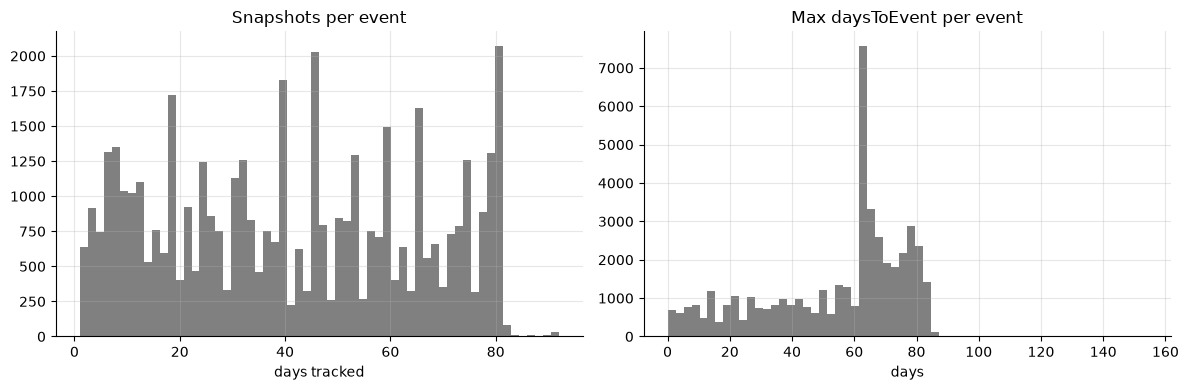

In [71]:
# How long is each event tracked? (matters for any time-series / panel modeling)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(events.snapshots, bins=60, color="gray"); axes[0].set(title="Snapshots per event", xlabel="days tracked")
axes[1].hist(events.max_daysToEvent, bins=60, color="gray"); axes[1].set(title="Max daysToEvent per event", xlabel="days")
fig.tight_layout()

,events,minPrice,medianPrice
weekday,,,
Monday,2428,72.49,112.57
Tuesday,4576,69.67,111.47
Wednesday,4996,69.34,109.93
Thursday,6480,69.13,108.17
Friday,10256,71.38,111.17
Saturday,11024,72.24,113.91
Sunday,6420,72.35,114.77


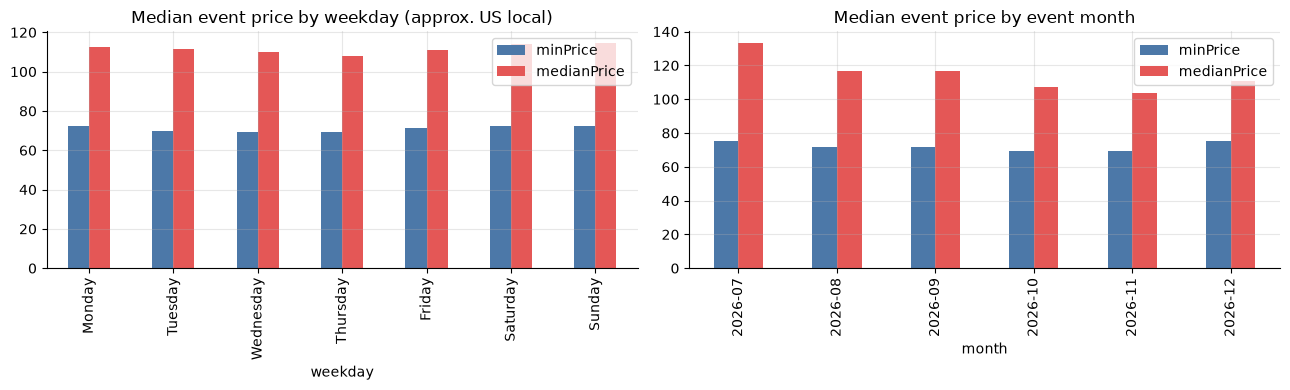

In [72]:
def price_by(col, order=None, min_events=1):
    g = events.groupby(col).agg(events=("eventId", "size"),
                                minPrice=("avg_minPrice", "median"),
                                medianPrice=("avg_medianPrice", "median"))
    g = g[g.events >= min_events]
    return g.reindex(order) if order is not None else g

days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
price_by("weekday", days)[TARGETS].plot.bar(ax=axes[0], color=[COLORS[t] for t in TARGETS],
                                            title="Median event price by weekday (approx. US local)")
price_by("month")[TARGETS].plot.bar(ax=axes[1], color=[COLORS[t] for t in TARGETS],
                                    title="Median event price by event month")
fig.tight_layout()
price_by("weekday", days)

In [73]:
top_cities = price_by("venueCity", min_events=200).sort_values("medianPrice", ascending=False)
print(f"{len(top_cities)} cities with >= 200 events")
top_cities

46 cities with >= 200 events


,events,minPrice,medianPrice
venueCity,,,
London,237,181.47,335.82
New York,1367,109.00,164.59
Las Vegas,1890,93.86,160.39
Montreal,255,77.66,140.61
Boise,226,80.46,137.82
Nashville,786,78.14,128.00
Orlando,305,71.80,125.42
Minneapolis,508,77.45,123.69
Pittsburgh,239,64.96,123.59


In [74]:
top_venues = price_by("venueName", min_events=100).sort_values("medianPrice", ascending=False)
pd.concat([top_venues.head(15), top_venues.tail(15)])

,events,minPrice,medianPrice
venueName,,,
The Carolina Opry,100,230.00,345.30
Red Rocks Amphitheatre,120,106.22,253.88
The Underground Theater at MGM Grand,113,108.62,204.33
Blue Note LA,114,166.01,203.17
Birdland,158,188.00,199.12
Orpheum Theatre,106,78.75,186.63
New York New York Theater,147,99.36,185.68
Blue Note,260,136.65,185.28
Ryman Auditorium,111,105.00,160.30


In [75]:
# High-cardinality categoricals: how concentrated are they? (informs target encoding vs one-hot)
for col in ["venueName", "venueCity"]:
    vc = events[col].value_counts()
    print(f"{col}: {len(vc):,} levels | top 50 cover {vc.head(50).sum() / vc.sum():.0%} of events | "
          f"{(vc == 1).sum():,} levels with a single event")

venueName: 2,991 levels | top 50 cover 13% of events | 425 levels with a single event
venueCity: 1,153 levels | top 50 cover 56% of events | 136 levels with a single event


### Text signals in `eventName`
Event names carry flags such as "Rescheduled", "Tribute", "Festival", and "VIP". Check whether they shift price.

In [76]:
keywords = {
    "rescheduled": r"reschedul",
    "tribute": r"tribute",
    "festival": r"fest",
    "vip/package": r"vip|package|meet\s*&?\s*greet",
    "tour": r"\btour\b",
    "symphony/orchestra": r"symphon|orchestra|philharmonic",
    "dj/edm": r"\bdj\b|edm|rave",
    "jazz": r"jazz",
    "country": r"country",
}
rows = []
for k, pat in keywords.items():
    m = events.eventName.str.contains(pat, case=False, regex=True)
    rows.append({"keyword": k, "events": m.sum(),
                 "median_medianPrice_with": events.loc[m, "avg_medianPrice"].median(),
                 "median_medianPrice_without": events.loc[~m, "avg_medianPrice"].median()})
kw = pd.DataFrame(rows).set_index("keyword")
kw["lift"] = kw.median_medianPrice_with / kw.median_medianPrice_without
kw.sort_values("lift", ascending=False)

,events,median_medianPrice_with,median_medianPrice_without,lift
keyword,,,,
vip/package,1,"1,151.72",111.65,10.32
festival,453,312.15,111.12,2.81
jazz,67,188.00,111.56,1.69
symphony/orchestra,1839,148.95,110.00,1.35
country,149,132.00,111.51,1.18
rescheduled,801,117.11,111.53,1.05
tribute,953,111.06,111.67,0.99
tour,117,95.56,111.69,0.86
dj/edm,495,90.58,111.92,0.81


In [77]:
events.nlargest(20, "avg_medianPrice")[["eventName", "venueName", "venueCity", "eventStartAt",
                                        "avg_minPrice", "avg_medianPrice", "avg_tickets"]]

,eventName,venueName,venueCity,eventStartAt,avg_minPrice,avg_medianPrice,avg_tickets
16081,Bop To The Top (18+ Event),Mercury Ballroom,Louisville,2026-08-13 02:00:00,"49,907.00","49,907.00",None
13289,John Fogerty,Casino Rama Resort,Rama,2026-08-23 00:00:00,"33,964.00","33,964.00",None
38405,2026 Lollapalooza - 2 Day Pass (Thursday 7/30 ...,Grant Park,Chicago,2026-07-31 04:59:00,"17,004.00","30,274.00",None
31407,Bill Murray and His Blood Brothers,Cerritos Center For The Performing Arts,Cerritos,2026-10-05 02:00:00,"22,138.00","22,138.00",None
28894,2026 Riot Fest - 2 Day Pass (9/18 and 9/19) (T...,Douglas Park,Chicago,2026-09-18 15:58:00,"3,476.79","17,406.97",None
28895,2026 Riot Fest - 2 Day Pass (9/18 and 9/20) (T...,Douglas Park,Chicago,2026-09-18 16:58:00,"3,477.00","17,406.97",None
28892,2026 Riot Fest - 2 Day Pass (9/19 and 9/20) (T...,Douglas Park,Chicago,2026-09-19 15:58:00,"3,467.57","16,986.25",None
3004,Bruno Mars,Wembley Stadium,London,2026-07-19 20:30:00,164.00,"16,635.00",None
9677,2026 Lollapalooza - 2 Day Pass (Thursday 7/30 ...,Grant Park,Chicago,2026-07-30 13:59:00,846.71,"16,538.14",None
4759,The Rock Orchestra By Candlelight,Bluestem Center for the Arts Amphitheatre,Moorhead,2026-09-06 01:00:00,144.21,"16,155.08",None


## 8. Numeric relationships and correlations

Prices are on the log scale here. **Leakage warning:** `p25Price`, `p75Price`, `maxPrice`, and the
before-fees prices come from the same snapshot as the target. They are near-duplicates of it and shouldn't be
used as features unless they're lagged.

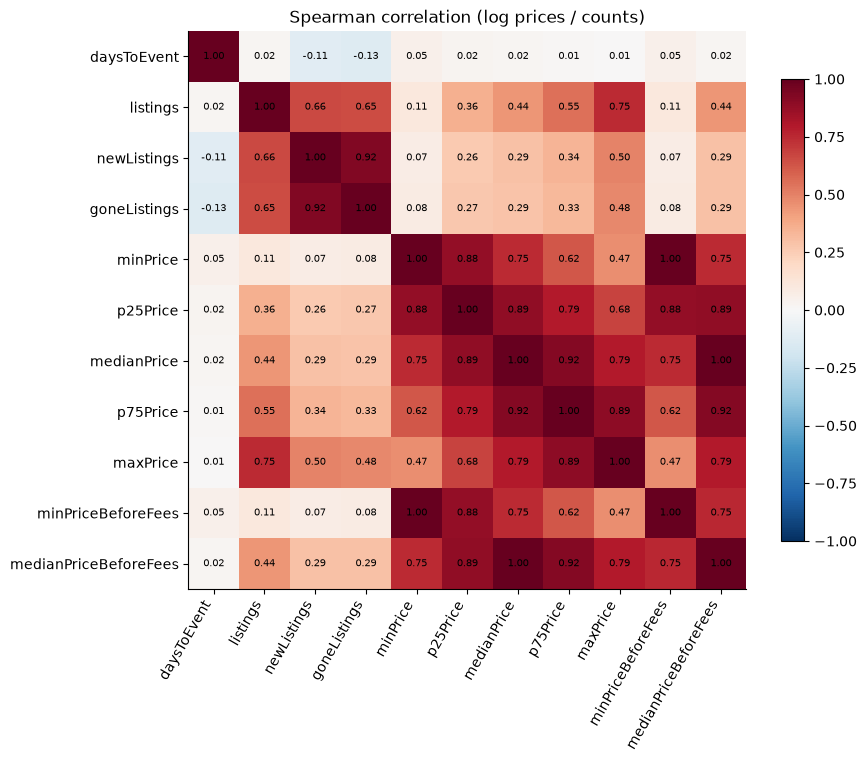

In [78]:
# tickets is omitted: it is null in every row of gametime
num = df[["daysToEvent", "listings", "newListings", "goneListings",
          "minPrice", "p25Price", "medianPrice", "p75Price", "maxPrice",
          "minPriceBeforeFees", "medianPriceBeforeFees"]].copy()
for c in ["listings", "minPrice", "p25Price", "medianPrice", "p75Price", "maxPrice",
          "minPriceBeforeFees", "medianPriceBeforeFees"]:
    num[c] = np.log1p(num[c])
corr = num.corr(method="spearman")

fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iat[i, j]:.2f}", ha="center", va="center", fontsize=7)
ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Spearman correlation (log prices / counts)");

In [79]:
corr.loc[["daysToEvent", "listings", "newListings", "goneListings"], TARGETS]

,minPrice,medianPrice
daysToEvent,0.05,0.02
listings,0.11,0.44
newListings,0.07,0.29
goneListings,0.08,0.29


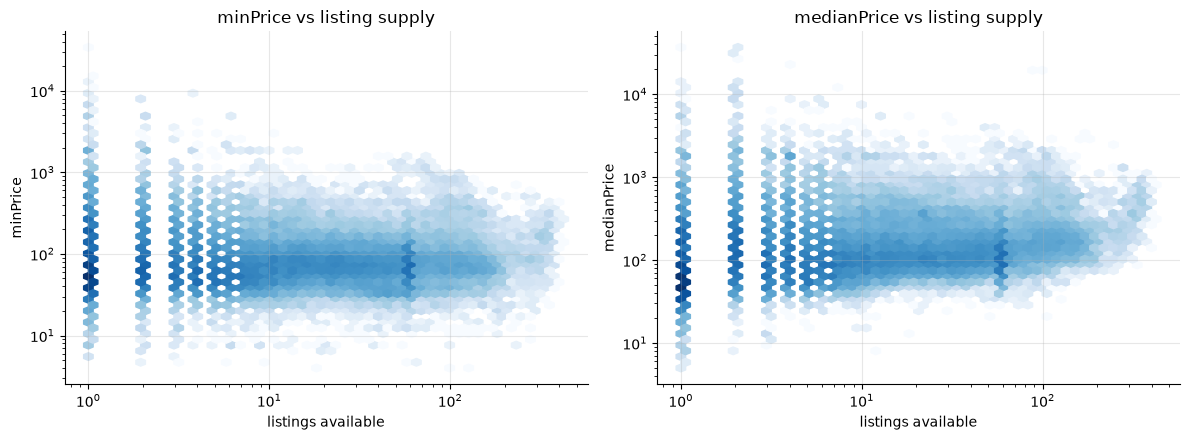

In [80]:
# tickets is all null, so listings is the supply measure
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, t in zip(axes, TARGETS):
    ax.hexbin(df.listings.clip(lower=1), df[t], xscale="log", yscale="log", gridsize=50, bins="log", cmap="Blues")
    ax.set(xlabel="listings available", ylabel=t, title=f"{t} vs listing supply")
fig.tight_layout()

## 9. Variance decomposition: how much is the event and how much is time?

If most of the variance in log price is *between* events, then event and venue features matter most. If a
large share is *within* events, then time-varying features (days to event, supply) are important.

In [81]:
rows = []
for t in TARGETS:
    y = np.log(df[t])
    event_mean = y.groupby(df.eventId).transform("mean")
    venue_mean = y.groupby(df.venueName).transform("mean")
    total = y.var()
    rows.append({"target": t,
                 "between_event_share": event_mean.var() / total,
                 "within_event_share": (y - event_mean).var() / total,
                 "explained_by_venue_alone": venue_mean.var() / total})
pd.DataFrame(rows).set_index("target")

,between_event_share,within_event_share,explained_by_venue_alone
target,,,
minPrice,0.90,0.10,0.44
medianPrice,0.87,0.13,0.49


## 10. Takeaways checklist for modeling

Fill these in after running the notebook:

- **Target choice:** `minPrice` or `medianPrice`? Compare skew, noise, and how much of each the features explain (sections 5 and 9).
- **Transform:** model `log(price)`; consider dropping or capping extreme `maxPrice`-driven outliers.
- **Rows to keep:** only `dayState = 'observed'` with non-null price (section 3).
- **Drop:** all-null/constant columns (section 2) and same-snapshot price siblings as features (section 8).
- **Candidate features:** `daysToEvent`, log `tickets`/`listings`, weekday/month, venue/city (target-encoded), eventName keyword flags.
- **Validation:** split by `eventId` (or by time) so the same event's snapshots don't appear in both train and test.

In [82]:
conn.close()